# Exploration des prix

Le chargement réutilise le package de production. Installer le groupe `notebooks` et sélectionner le noyau du projet.

In [1]:
from forecasting.data_loader import load_prices

df = load_prices()
df.head()

DATE,PRODUCTS,VALUE
date,str,f64
2024-01-01,"""Aliments pour bébés, 128 milli…",1.59
2024-01-01,"""Amandes, 200 grammes""",5.01
2024-01-01,"""Arachides, 450 grammes""",4.13
2024-01-01,"""Avocat, unité""",1.7
2024-01-01,"""Bacon, 500 grammes""",6.48


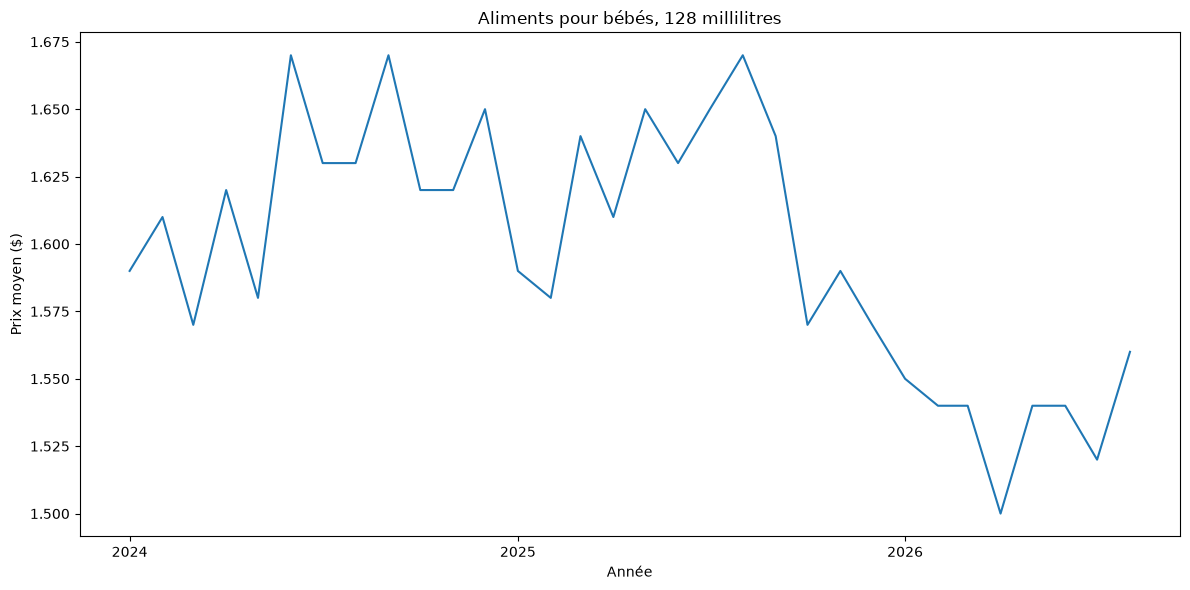

In [2]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Choose one product from available_products, then rerun this cell.
available_products = df.get_column("PRODUCTS").unique().sort().to_list()
selected_product = available_products[0]  # Replace with a product name if needed.

product_df = (
    df.filter(pl.col("PRODUCTS") == selected_product)
    .sort("DATE")
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(product_df.get_column("DATE").to_list(),
        product_df.get_column("VALUE").to_list())
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Année")
ax.set_ylabel("Prix moyen ($)")
ax.set_title(selected_product)
fig.tight_layout()
plt.show()
